In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [41]:
df = pd.read_csv("C:\\Users\\wasim\\Downloads\\diamonds.csv\\diamonds.csv")

In [42]:
df.head()

,Unnamed: 0,carat,cut,color,clarity,depth,table,price,x,y,z
0,1,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,2,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,3,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,4,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,5,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [43]:
df.info

<bound method DataFrame.info of        Unnamed: 0  carat        cut color clarity  depth  table  price     x  \
0               1   0.23      Ideal     E     SI2   61.5   55.0    326  3.95   
1               2   0.21    Premium     E     SI1   59.8   61.0    326  3.89   
2               3   0.23       Good     E     VS1   56.9   65.0    327  4.05   
3               4   0.29    Premium     I     VS2   62.4   58.0    334  4.20   
4               5   0.31       Good     J     SI2   63.3   58.0    335  4.34   
...           ...    ...        ...   ...     ...    ...    ...    ...   ...   
53935       53936   0.72      Ideal     D     SI1   60.8   57.0   2757  5.75   
53936       53937   0.72       Good     D     SI1   63.1   55.0   2757  5.69   
53937       53938   0.70  Very Good     D     SI1   62.8   60.0   2757  5.66   
53938       53939   0.86    Premium     H     SI2   61.0   58.0   2757  6.15   
53939       53940   0.75      Ideal     D     SI2   62.2   55.0   2757  5.83   

       

In [44]:
df.isnull().sum()

Unnamed: 0    0
carat         0
cut           0
color         0
clarity       0
depth         0
table         0
price         0
x             0
y             0
z             0
dtype: int64

In [45]:
df.duplicated().sum()

np.int64(0)

In [46]:
df.describe()

,Unnamed: 0,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,26970.500000,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,15571.281097,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,1.000000,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,13485.750000,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,26970.500000,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,40455.250000,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,53940.000000,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


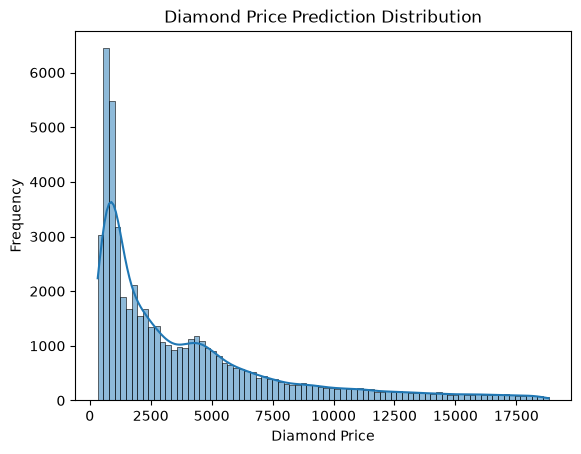

In [47]:
sns.histplot(df["price"], kde=True)
plt.title("Diamond Price Prediction Distribution")
plt.xlabel("Diamond Price")
plt.ylabel("Frequency")
plt.show()

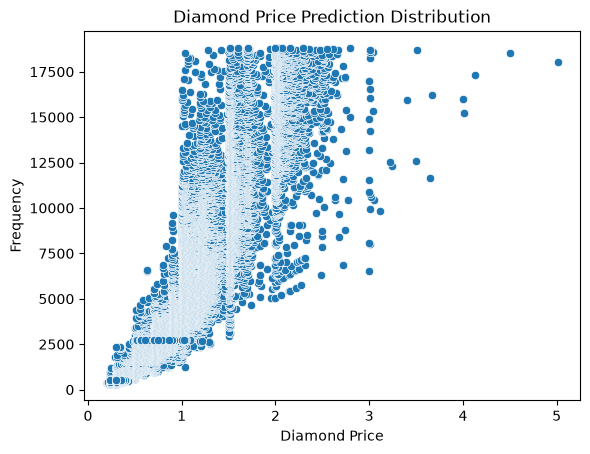

In [48]:
sns.scatterplot(
    x='carat',
    y='price',
    data=df
)
plt.title("Diamond Price Prediction Distribution")
plt.xlabel("Diamond Price")
plt.ylabel("Frequency")
plt.show()

In [49]:
correlation = df.corr(numeric_only=True)
correlation


,Unnamed: 0,carat,depth,table,price,x,y,z
Unnamed: 0,1.000000,-0.377983,-0.034800,-0.100830,-0.306873,-0.405440,-0.395843,-0.399208
carat,-0.377983,1.000000,0.028224,0.181618,0.921591,0.975094,0.951722,0.953387
depth,-0.034800,0.028224,1.000000,-0.295779,-0.010647,-0.025289,-0.029341,0.094924
table,-0.100830,0.181618,-0.295779,1.000000,0.127134,0.195344,0.183760,0.150929
price,-0.306873,0.921591,-0.010647,0.127134,1.000000,0.884435,0.865421,0.861249
x,-0.405440,0.975094,-0.025289,0.195344,0.884435,1.000000,0.974701,0.970772
y,-0.395843,0.951722,-0.029341,0.183760,0.865421,0.974701,1.000000,0.952006
z,-0.399208,0.953387,0.094924,0.150929,0.861249,0.970772,0.952006,1.000000


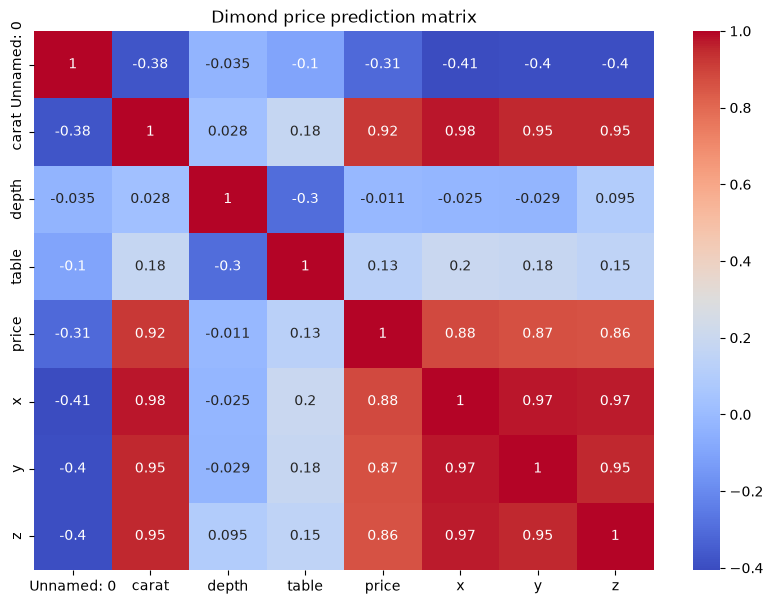

In [50]:
plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm'
)
plt.title("Dimond price prediction matrix")
plt.show()

In [51]:
print(df.columns)

Index(['Unnamed: 0', 'carat', 'cut', 'color', 'clarity', 'depth', 'table',
       'price', 'x', 'y', 'z'],
      dtype='str')


In [66]:
X = df.drop(columns=["price"])
y = df["price"]

In [67]:
num_cols = X.select_dtypes(include=["number"]).columns
cat_cols = X.select_dtypes(include=["object", "category"]).columns

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)
])


C:\Users\wasim\AppData\Local\Temp\ipykernel_70616\3523767630.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category"]).columns


In [68]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

MAE: 737.1513665933207
RMSE: 1135.2116445190636
R2 Score: 0.9189331350419386


In [69]:
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

X = df.drop(columns=["price"])
y = df["price"]

print(X.dtypes)

carat      float64
cut            str
color          str
clarity        str
depth      float64
table      float64
x          float64
y          float64
z          float64
dtype: object


In [74]:
print(y_pred[:10])

[ 711.88577262 3191.72583727 1947.2464112  2077.29062598 9878.99820896
 3932.58482532 2372.62585284 2380.08706701 2844.11827559 6199.23891652]


In [94]:
from sklearn.metrics import mean_squared_error
mae = mean_absolute_error(y_test, y_pred)
print("MAE:", mae)

MAE: 737.1513665933207


In [96]:

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("RMSE:", rmse)
r2 = r2_score(y_test, y_pred)

RMSE: 1135.2116445190636


In [79]:
comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})
comparison.head(10)

,Actual Price,Predicted Price
0,559,711.885773
1,2201,3191.725837
2,1238,1947.246411
3,1304,2077.290626
4,6901,9878.998209
5,3011,3932.584825
6,1765,2372.625853
7,1679,2380.087067
8,2102,2844.118276
9,4789,6199.238917


In [86]:
rf_model = Pipeline([
    ("preprocessing", preprocessor),
    ("regression", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

In [90]:
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, y_pred_rf))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_rf)))
print("R2 Score:", r2_score(y_test, y_pred_rf))

MAE: 269.8913375949394
RMSE: 549.6853197510263
R2 Score: 0.9809928071673821


In [91]:
rf_pred = rf_model.predict(X_test)

In [99]:
rf_mae = mean_absolute_error(y_test, y_pred_rf)
rf_rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))
rf_r2 = r2_score(y_test, y_pred_rf)

In [100]:
results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Random Forest'
    ],
    
    'MAE': [
        mae,
        rf_mae
    ],
    
    'RMSE': [
        rmse,
        rf_rmse
    ],
    
    'R2 Score': [
        r2,
        rf_r2
    ]
})

results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,737.151367,1135.211645,0.918933
1,Random Forest,269.891338,549.685320,0.980993


In [103]:
importance = pd.Series(
    rf_model.named_steps['regression'].feature_importances_,
    index=rf_model.named_steps['preprocessing'].get_feature_names_out()
)

importance = importance.sort_values(ascending=False)

print(importance)

num__carat            0.628834
num__y                0.257220
cat__clarity_SI2      0.019442
cat__clarity_I1       0.014997
cat__clarity_SI1      0.014450
cat__color_J          0.010341
cat__color_I          0.007244
cat__clarity_VS2      0.007099
cat__color_H          0.005640
cat__clarity_VS1      0.005599
num__x                0.005582
num__z                0.005249
num__depth            0.003176
cat__color_D          0.002827
cat__color_G          0.002596
num__table            0.002186
cat__color_E          0.001654
cat__color_F          0.001444
cat__clarity_VVS2     0.001166
cat__cut_Ideal        0.001003
cat__clarity_IF       0.000729
cat__clarity_VVS1     0.000492
cat__cut_Premium      0.000368
cat__cut_Very Good    0.000277
cat__cut_Good         0.000243
cat__cut_Fair         0.000143
dtype: float64


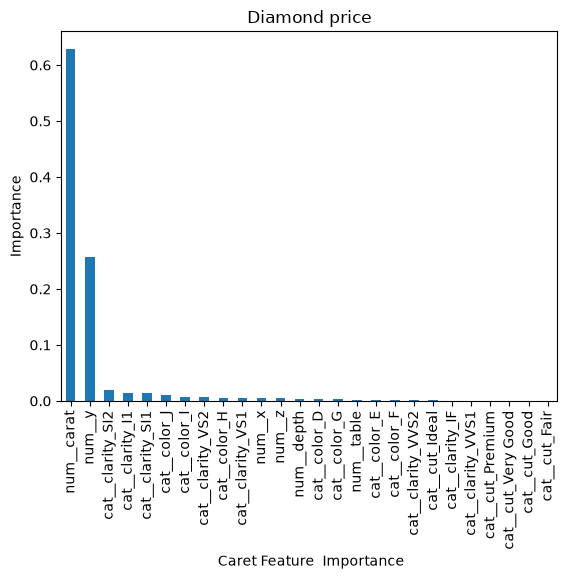

In [105]:
importance.plot(kind='bar')
plt.title("Diamond price")
plt.xlabel(" Caret Feature  Importance")
plt.ylabel("Importance")
plt.show()

In [106]:
df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [110]:
new_diomand = pd.DataFrame({
    'carat': [0.30],
    'cut': ['Ideal'],
    'color': ['E'],
    'clarity': ['SI1'],
    'depth': [61.5],
    'table': [55.0],
    'x': [4.3],
    'y': [4.3],
    'z': [2.6]
})

In [111]:
new_diomand = new_diomand[X.columns]

predict_price = rf_model.predict(new_diomand)

print("Diamond Price:", predict_price[0])

Diamond Price: 576.165


In [115]:
import joblib
joblib.dump(rf_model, "diamond_price_model.pkl")

['diamond_price_model.pkl']

In [116]:
loaded_model = joblib.load(
    "diamond_price_model.pkl"
)